# Multigroup collapsing

This notebook solves a homogeneous diffusion eigenvalue problem, uses the direct spectrum to collapse the multigroup constants, and compares:

- collapsed constants and scattering matrices;
- $k_\mathrm{eff}$ and flux before and after collapsing;
- preservation of fission, capture, absorption, production, scattering, and total rates;
- the trade-off between preserving the transport sum rule and preserving the leakage term $D_gB^2\Phi_g$.

The **Configuration** cell is the only cell that needs to be edited to select the system, change $B^2$, select the diffusion-collapse method, and specify the requested numbers of groups.

## 1. From the transport equation to the multigroup equations

For energy group $g$, the steady-state transport equation for the angular flux $\phi_g(\mathbf r,\mathbf\Omega)$ is

$$
\mathbf\Omega\!\cdot\!\nabla\phi_g(\mathbf r,\mathbf\Omega)
+\Sigma_{t,g}\phi_g(\mathbf r,\mathbf\Omega)
=\sum_{g'=1}^G\oint\!\Sigma_{s,g'\to g}(\mathbf\Omega'\!\to\!\mathbf\Omega)
\phi_{g'}(\mathbf r,\mathbf\Omega')\,d\Omega'
+\frac{\chi_g}{4\pi k}\sum_{g'=1}^G\nu\Sigma_{f,g'}\Phi_{g'}(\mathbf r).
$$

After integrating over angle, the scalar flux is $\Phi_g(\mathbf r)=\oint\phi_g(\mathbf r,\mathbf\Omega)\,d\Omega$. Adopting the $P_1$ closure (see the next lectures for details) gives

$$
\nabla\!\cdot\!\mathbf J_g+\Sigma_{t,g}\Phi_g
=\sum_{g'=1}^G\Sigma_{s,g'\to g}\Phi_{g'}
+\frac{\chi_g}{k}\sum_{g'=1}^G\nu\Sigma_{f,g'}\Phi_{g'},
\qquad
\mathbf J_g=-D_g\nabla\Phi_g,
\qquad
D_g=\frac{1}{3\Sigma_{tr,g}}.
$$

## 2. Buckling approximation: streaming becomes $D_gB^2\Phi_g$

Separating the spatial dependence through the fundamental mode and using the Helmholtz relation,

$$-\nabla^2\Phi_g(\mathbf r) = B^2\Phi_g(\mathbf r),$$

gives

$$
-\nabla\!\cdot D_g\nabla\Phi_g
\;\longrightarrow\;D_gB^2\Phi_g,
$$

and therefore

$$
(\Sigma_{t,g}+D_gB^2)\Phi_g
-\sum_{g'}\Sigma_{s,g'\to g}\Phi_{g'}
=\frac{\chi_g}{k}\sum_{g'}\nu\Sigma_{f,g'}\Phi_{g'}.
$$

In matrix form, with $S_{g,g'}=\Sigma_{s,g'\to g}$,

$$
\left[\operatorname{diag}(\boldsymbol\Sigma_t+\mathbf D B^2)-\mathbf S\right]\boldsymbol\Phi
=\frac{1}{k}\,\boldsymbol\chi(\boldsymbol\nu\boldsymbol\Sigma_f)^T\boldsymbol\Phi.
$$

Throughout the notebook, **`B2` is an explicit parameter** in cm$^{-2}$. For a bare cylinder, $B^2=(\pi/H)^2+(j_0/R)^2$, where $j_0=2.4048$ is the first zero of the Bessel function $J$. 

The shape of the system is not imposed here, as we prescribe directly the value of the buckling.

The advantage of this approach is that the set of differential equations becomes naturally a set of linear algebraic equations.

## 3. Collapsing formulas and preserved rates

For a coarse group $G$ made of fine groups $g\in G$, define

$$
\Phi_G=\sum_{g\in G}\Phi_g,
\qquad
\Sigma_{x,G}=\frac{\displaystyle\sum_{g\in G}\Sigma_{x,g}\Phi_g}{\Phi_G}.
$$

For scattering from coarse group $G'$ to coarse group $G$,

$$
\Sigma_{s,G'\to G}=
\frac{\displaystyle\sum_{g'\in G'}\Phi_{g'}\displaystyle\sum_{g\in G}\Sigma_{s,g'\to g}}{\Phi_{G'}}.
$$

Up to numerical roundoff, these definitions exactly preserve linear reaction rates evaluated with the **collapsing spectrum**. For fission production, $\nu$ is additionally averaged using the fission rate as its weight.

Two alternative treatments of diffusion are available:

1. **`transport`**: collapse $\Sigma_{tr}$ as a cross section and reconstruct $D_G=1/(3\Sigma_{tr,G})$. This preserves the transport-cross-section rate and the $P_0$ sum rule, but generally not leakage.
2. **`direct-D`**: collapse $D$ directly with the flux-weighted formula used for cross sections. This preserves $\sum_gD_gB^2\Phi_g$, but the implied $1/(3D_G)$ no longer preserves $\Sigma_{tr}$ or its $P_0$ sum rule.

The dedicated diagnostics below display this trade-off explicitly.

In [1]:
# --- Import standard-library data containers and path utilities
from dataclasses import dataclass
from pathlib import Path

# --- Import the numerical, tabular, plotting, and eigensolver libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.linalg import eig

# --- Import the project-specific multigroup data reader and validator
from MGC import MGC

# --- Set common plotting and table-display defaults
# plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (8, 4.8), "font.size": 11})
pd.options.display.float_format = "{:,.6e}".format


# --- Add low-opacity major and minor grids on both plot axes
def add_major_minor_grid(ax, major_alpha=0.18, minor_alpha=0.08, axisbelow=True):
    ax.minorticks_on()
    ax.set_axisbelow(axisbelow)
    ax.grid(True, which="major", axis="both", color="0.40", lw=0.65, alpha=major_alpha)
    ax.grid(True, which="minor", axis="both", color="0.55", lw=0.40, alpha=minor_alpha)


## 4. Configuration — edit this cell

`SYSTEM` can be `"LFR"` or `"LWR"`. `B2` directly controls leakage. `DIFFUSION_COLLAPSE` selects whether the transport cross section or the diffusion coefficient is preserved. `CUSTOM_BOUNDARIES` is a list of coarse grids; each coarse grid is a descending list of boundaries present in the selected fine grid. Grids with the same number of groups are allowed and receive distinct labels such as `4G_A` and `4G_B`.

In [2]:
# --- Select the physical system and leakage parameter
SYSTEM = "LFR"                    # "LFR" (120 groups) or "LWR" (70 groups)
B2 = 1.80e-3                      # geometric/material buckling [cm^-2]

# --- Define explicit custom grids equivalent to the former 8G, 4G, 2G, and 1G examples
CUSTOM_BOUNDARIES_BY_SYSTEM = {
    "LFR": [
        [20.0, 1.80566495068, 0.288520709274, 0.0461016866106,
         0.00736642272124, 0.00117705419687, 0.000188077257416,
         3.00521886343e-05, 1.0e-11],
        [20.0, 0.288520709274, 0.00736642272124, 0.000188077257416, 1.0e-11],
        [20.0, 0.00736642272124, 1.0e-11],
        [20.0, 1.0e-11],
    ],
    "LWR": [
        [20.0, 0.111, 0.0014251, 9.877e-06, 1.123e-06, 8.5e-07, 2.8e-07, 5.0e-08, 1.0e-11],
        [20.0, 0.0014251, 1.123e-06, 2.8e-07, 1.0e-11],
        [20.0, 1.123e-06, 1.0e-11],
        [20.0, 1.0e-11],
    ],
}
CUSTOM_BOUNDARIES = CUSTOM_BOUNDARIES_BY_SYSTEM[SYSTEM]
PLOT_GRID = "4G_A"              # unique grid label used in detailed plots

# --- Set the common energy range for every energy-dependent plot [MeV]
E_min = 1.0e-11
E_max = 20.0
x_lim = (E_min, E_max)

# --- Select how diffusion data are collapsed and interpreted
DIFFUSION_COLLAPSE = "direct-D" # "transport" or "direct-D"
P1_CONSISTENT = False            # please do not change this 

# --- Locate the precomputed group-constant files
DATA_DIR = Path.cwd().joinpath("data")             # set explicitly if launched elsewhere

# --- Validate the inputs and summarize the selected case
assert SYSTEM in {"LFR", "LWR"}
assert B2 >= 0.0
assert 0.0 < E_min < E_max
assert DIFFUSION_COLLAPSE in {"transport", "direct-D"}
print(f"System: {SYSTEM}; B² = {B2:.4e} cm^-2; diffusion collapse: {DIFFUSION_COLLAPSE}")

System: LFR; B² = 1.8000e-03 cm^-2; diffusion collapse: direct-D


In [3]:
# --- Define the LFR 120-group energy grid in MeV
# Do not change these values: they index the precomputed group constants.
e120_asc = np.r_[
    1.0e-11,
    np.geomspace(5.0e-7, 1.0e-5, 6),
    np.geomspace(1.0e-5, 1.0e1, 114)[1:],
    2.0e1,
]
E_LFR = e120_asc[::-1] # multi-group data are stored in descending order of energy

# --- Define the LWR 70-group energy grid in MeV
E_LWR = np.array([
    1.00000e-11, 5.00000e-09, 1.00000e-08, 1.50000e-08, 2.00000e-08,
    2.50000e-08, 3.00000e-08, 3.50000e-08, 4.20000e-08, 5.00000e-08,
    5.80000e-08, 6.70000e-08, 8.00000e-08, 1.00000e-07, 1.40000e-07,
    1.80000e-07, 2.20000e-07, 2.50000e-07, 2.80000e-07, 3.00000e-07,
    3.20000e-07, 3.50000e-07, 4.00000e-07, 5.00000e-07, 6.25000e-07,
    7.80000e-07, 8.50000e-07, 9.10000e-07, 9.50000e-07, 9.72000e-07,
    9.96000e-07, 1.02000e-06, 1.04500e-06, 1.07100e-06, 1.09700e-06,
    1.12300e-06, 1.15000e-06, 1.30000e-06, 1.50000e-06, 1.85500e-06,
    2.10000e-06, 2.60000e-06, 3.30000e-06, 4.00000e-06, 9.87700e-06,
    1.59680e-05, 2.77000e-05, 4.80520e-05, 7.55014e-05, 1.48728e-04,
    3.67262e-04, 9.06898e-04, 1.42510e-03, 2.23945e-03, 3.51910e-03,
    5.53000e-03, 9.11800e-03, 1.50300e-02, 2.47800e-02, 4.08500e-02,
    6.74300e-02, 1.11000e-01, 1.83000e-01, 3.02500e-01, 5.00000e-01,
    8.21000e-01, 1.35300e+00, 2.23100e+00, 3.67900e+00, 6.06550e+00,
    2.00000e+01,
])[::-1] # multi-group data are stored in descending order of energy

# --- Map each system to its energy grid and JSON dataset
ENERGY_GRIDS = {"LFR": E_LFR, "LWR": E_LWR}
MATERIALS = {"LFR": "LFR_120G", "LWR": "LWR_70G"}

# --- Check that the boundary arrays define 120 and 70 groups
assert len(E_LFR) == 121 and len(E_LWR) == 71

In [4]:
# --- Store one complete set of multigroup constants
@dataclass
class MGData:
    name: str
    edges: np.ndarray
    Tot: np.ndarray
    Capt: np.ndarray
    Fiss: np.ndarray
    Nubar: np.ndarray
    Chit: np.ndarray
    S0: np.ndarray                 # S0[arrival, departure]
    Transpxs: np.ndarray
    Diffcoef: np.ndarray
    collapse_flux: np.ndarray | None = None
    diffusion_mode: str = "fine"

    @property
    def nG(self):
        return len(self.edges) - 1


# --- Load and validate the selected fine-group dataset through MGC.py
def load_reference(system, data_dir=DATA_DIR):
    edges = ENERGY_GRIDS[system].copy()
    name = MATERIALS[system]
    if not (data_dir / f"{name}.json").exists():
        raise FileNotFoundError(f"Cannot find {name}.json in {data_dir.resolve()}")
    # --- Let MGC read the JSON and complete dependent nuclear data
    mgc = MGC(
        uniName=name, energygrid=edges, datapath=str(data_dir),
        P1consistent=P1_CONSISTENT, datacheck=True,
    )
    # --- Verify vector and scattering-matrix dimensions before use
    arrays = (mgc.Tot, mgc.Capt, mgc.Fiss, mgc.Nubar, mgc.Chit, mgc.Transpxs, mgc.Diffcoef)
    if any(np.asarray(a).shape != (mgc.nE,) for a in arrays):
        raise ValueError("A multigroup constant has dimensions incompatible with the energy grid.")
    if np.asarray(mgc.S0).shape != (mgc.nE, mgc.nE):
        raise ValueError("The S0 matrix has dimensions incompatible with the energy grid.")
    # --- Copy MGC data into the lightweight notebook data container
    return MGData(
        name=name, edges=edges,
        Tot=mgc.Tot.copy(), Capt=mgc.Capt.copy(), Fiss=mgc.Fiss.copy(),
        Nubar=mgc.Nubar.copy(), Chit=mgc.Chit.copy(), S0=mgc.S0.copy(),
        Transpxs=mgc.Transpxs.copy(), Diffcoef=mgc.Diffcoef.copy(),
    )


# --- Assemble the loss/scattering operator A and fission operator F
def operators(data, b2):
    A = np.diag(data.Tot + data.Diffcoef * b2) - data.S0
    F = np.outer(data.Chit, data.Nubar * data.Fiss)
    return A, F


# --- Solve the generalized k-eigenvalue problem and normalize the flux
def solve_keff(data, b2):
    # Solve F Phi = k A Phi and return the dominant physical mode.
    A, F = operators(data, b2)
    # --- Compute all modes and retain the dominant positive real mode
    values, vectors = eig(F, A)
    physical = np.isfinite(values) & (np.abs(values.imag) < 1.0e-9) & (values.real > 0.0)
    if not np.any(physical):
        raise RuntimeError("No positive real eigenvalue was found.")
    candidates = np.flatnonzero(physical)
    i = candidates[np.argmax(values.real[candidates])]
    k = float(values[i].real)
    phi = vectors[:, i].real
    # --- Enforce a physically positive flux and unit integral
    # Numerical noise may return a uniformly negative eigenvector.
    if phi.sum() < 0.0:
        phi *= -1.0
    tol = 1.0e-10 * max(1.0, np.max(np.abs(phi)))
    if phi.min() < -tol:
        raise RuntimeError("The dominant eigenvector is not physically positive.")
    phi = np.clip(phi, 0.0, None)
    phi /= phi.sum()
    # --- Quantify how accurately the selected eigenpair satisfies F Phi = k A Phi
    residual = np.linalg.norm(F @ phi - k * A @ phi) / np.linalg.norm(F @ phi)
    return {"k": k, "phi": phi, "residual": residual}

In [5]:
# --- Validate and snap user-supplied boundaries to the fine grid
def snap_custom_edges(fine_edges, requested):
    requested = np.asarray(requested, dtype=float)
    if requested.ndim != 1 or len(requested) < 2 or not np.all(np.diff(requested) < 0):
        raise ValueError("Each custom grid must be a strictly descending 1D array.")
    snapped = []
    for edge in requested:
        i = int(np.argmin(np.abs(fine_edges - edge)))
        if not np.isclose(fine_edges[i], edge, rtol=1.0e-8, atol=1.0e-14):
            raise ValueError(f"Boundary {edge:.8e} MeV is not present in the fine grid.")
        snapped.append(fine_edges[i])
    snapped = np.asarray(snapped)
    if not (np.isclose(snapped[0], fine_edges[0]) and np.isclose(snapped[-1], fine_edges[-1])):
        raise ValueError("The collapsed grid must cover the full energy range.")
    return snapped


# --- Validate multiple custom grids and assign unique nG_letter labels
def prepare_custom_grids(fine_edges, requested_grids):
    if not isinstance(requested_grids, (list, tuple)) or len(requested_grids) == 0:
        raise ValueError("CUSTOM_BOUNDARIES must be a non-empty list of boundary lists.")

    labels_per_group_count = {}
    prepared = {}
    for grid_number, requested in enumerate(requested_grids, start=1):
        try:
            edges = snap_custom_edges(fine_edges, requested)
        except (TypeError, ValueError) as error:
            raise ValueError(f"Invalid custom grid #{grid_number}: {error}") from error

        n_groups = len(edges) - 1
        occurrence = labels_per_group_count.get(n_groups, 0)
        if occurrence >= 26:
            raise ValueError(f"At most 26 custom grids with {n_groups} groups are supported.")
        grid_id = f"{n_groups}G_{chr(ord('A') + occurrence)}"
        labels_per_group_count[n_groups] = occurrence + 1
        prepared[grid_id] = edges
    return prepared


# --- Convert coarse boundaries into lists of contained fine-group indices
def group_bins(fine_edges, coarse_edges):
    indices = []
    for edge in coarse_edges:
        i = int(np.argmin(np.abs(fine_edges - edge)))
        if not np.isclose(fine_edges[i], edge, rtol=1.0e-8, atol=1.0e-14):
            raise ValueError(f"Boundary {edge:.8e} is not present in the fine grid.")
        indices.append(i)
    return [np.arange(indices[j], indices[j + 1]) for j in range(len(indices) - 1)]


# --- Collapse all multigroup constants with the supplied fine spectrum
def collapse(data, phi, coarse_edges, diffusion_mode="transport"):
    if diffusion_mode not in {"transport", "direct-D"}:
        raise ValueError("diffusion_mode must be 'transport' or 'direct-D'.")
    bins = group_bins(data.edges, coarse_edges)
    Phi = np.array([phi[b].sum() for b in bins])
    if np.any(Phi <= 0.0):
        raise ValueError("A coarse group has zero flux, so collapsing is not possible.")

    def flux_average(x):
        return np.array([np.dot(x[b], phi[b]) / Phi[j] for j, b in enumerate(bins)])

    # --- Collapse scalar cross sections with flux weighting
    Tot = flux_average(data.Tot)
    Capt = flux_average(data.Capt)
    Fiss = flux_average(data.Fiss)
    collapsed_transpxs = flux_average(data.Transpxs)

    # --- Collapse each departure-to-arrival scattering block
    S0 = np.zeros((len(bins), len(bins)))
    for J, departure in enumerate(bins):
        for I, arrival in enumerate(bins):
            block = data.S0[np.ix_(arrival, departure)]
            S0[I, J] = np.sum(block * phi[departure][None, :]) / Phi[J]

    # --- Collapse nu with fission-rate weighting and sum chi probabilities
    fission_rates = np.array([np.dot(data.Fiss[b], phi[b]) for b in bins])
    Nubar = np.array([
        np.dot(data.Nubar[b] * data.Fiss[b], phi[b]) / fission_rates[j]
        if fission_rates[j] > 0.0 else 0.0
        for j, b in enumerate(bins)
    ])
    Chit = np.array([data.Chit[b].sum() for b in bins])
    Chit /= Chit.sum()

    # --- Apply the selected transport-preserving or leakage-preserving D treatment
    if diffusion_mode == "transport":
        Transpxs = collapsed_transpxs
        Diffcoef = 1.0 / (3.0 * Transpxs)
    else:
        Diffcoef = flux_average(data.Diffcoef)
        Transpxs = 1.0 / (3.0 * Diffcoef)

    # --- Return a new coarse dataset without modifying the fine one
    return MGData(
        name=f"{data.name} → {len(bins)}G", edges=np.asarray(coarse_edges),
        Tot=Tot, Capt=Capt, Fiss=Fiss, Nubar=Nubar, Chit=Chit,
        S0=S0, Transpxs=Transpxs, Diffcoef=Diffcoef, collapse_flux=Phi,
        diffusion_mode=diffusion_mode,
    )


# --- Integrate the principal collision and leakage rates over energy
def reaction_rates(data, phi, b2):
    return {
        "Fission": np.dot(data.Fiss, phi),
        "Capture": np.dot(data.Capt, phi),
        "Absorption": np.dot(data.Fiss + data.Capt, phi),
        "Fission production": np.dot(data.Nubar * data.Fiss, phi),
        "Total scattering": np.dot(data.S0.sum(axis=0), phi),
        "Total": np.dot(data.Tot, phi),
        "Leakage DB²Φ": np.dot(data.Diffcoef * b2, phi),
    }

## 5. Fine-grid solution

The scalar flux below is calculated from the eigenvalue problem; it is not the `Flux` tally stored in the JSON file. The selected normalization is $\sum_g\Phi_g=1$.

In [6]:
# --- Load the selected fine-group constants
reference = load_reference(SYSTEM)
# --- Solve the fine-group problem at the selected buckling
fine_solution = solve_keff(reference, B2)

# --- Report the fine-grid eigenvalue and numerical residual
print(f"Material: {reference.name} ({reference.nG} groups)")
print(f"k_eff = {fine_solution['k']:.5f}")
print(f"relative residual = {fine_solution['residual']:.2e}")

Material: LFR_120G (120 groups)
k_eff = 1.00717
relative residual = 1.24e-14


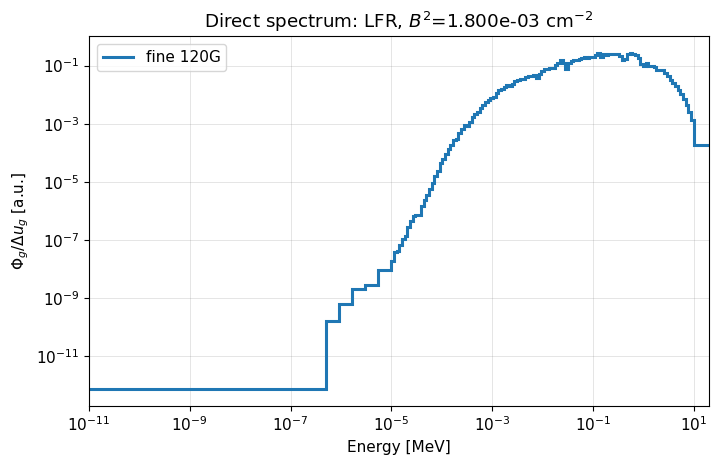

In [7]:
# --- Draw groupwise-constant data stored with descending energy boundaries
def step_plot(ax, edges, values, **kwargs):
    return ax.stairs(np.asarray(values)[::-1], np.asarray(edges)[::-1], baseline=None, **kwargs)


# --- Convert integrated group flux to flux per unit lethargy before plotting
def plot_flux(ax, data, phi, **kwargs):
    du = np.log(data.edges[:-1] / data.edges[1:])
    return step_plot(ax, data.edges, phi / du, **kwargs)


# --- Plot the fine-group direct spectrum
fig, ax = plt.subplots()
plot_flux(ax, reference, fine_solution["phi"], lw=2.2, label=f"fine {reference.nG}G")
ax.set(xscale="log", yscale="log", xlabel="Energy [MeV]", ylabel=r"$\Phi_g/\Delta u_g$ [a.u.]",
       title=rf"Direct spectrum: {SYSTEM}, $B^2$={B2:.3e} cm$^{{-2}}$")
ax.set_xlim(x_lim)
add_major_minor_grid(ax)
ax.legend()
plt.show()

### Note on lethargy

**Lethargy** is a logarithmic energy coordinate, defined with respect to a maximum reference energy $E_{\max}$:

$$u(E)=\log\!\left(\frac{E_{\max}}{E}\right).$$

As energy decreases, lethargy increases. For a group bounded by $E_{g,\mathrm{high}}$ and $E_{g,\mathrm{low}}$, its lethargy width is $\Delta u_g=\log(E_{g,\mathrm{high}}/E_{g,\mathrm{low}})$. Therefore, quantities displayed as $\Phi_g/\Delta u_g$ are expressed per unit lethargy.

## 6. Direct spectrum with and without leakage

The infinite-medium solution ($B^2=0$) is compared directly with the solution at the selected nonzero `B2`. Both spectra are normalized to unit integrated flux. The lower panel shows their pointwise ratio, making the spectral distortion caused by leakage visible in addition to the change in $k$.

If `B2` is set to zero, the two curves coincide by construction.

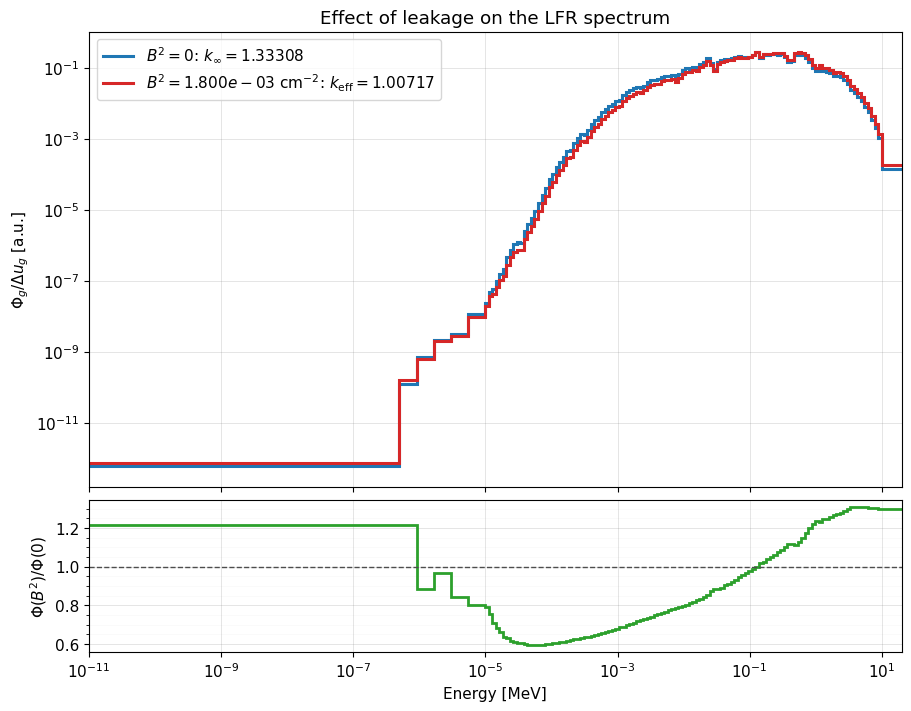

k(B²=0)         = 1.33308
k(B²=1.800e-03) = 1.00717
Leakage effect   = -3.26e+04 pcm


In [8]:
# --- Solve the same fine problem without leakage
infinite_solution = solve_keff(reference, 0.0)

# --- Compare the two spectra on a common normalization
fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(9, 7), sharex=True,
    gridspec_kw={"height_ratios": [3, 1]}, constrained_layout=True,
)
plot_flux(ax1, reference, infinite_solution["phi"], color="C0", lw=2.2,
          label=rf"$B^2=0$: $k_\infty={infinite_solution['k']:.5f}$")
plot_flux(ax1, reference, fine_solution["phi"], color="C3", lw=2.2,
          label=rf"$B^2={B2:.3e}$ cm$^{{-2}}$: $k_\mathrm{{eff}}={fine_solution['k']:.5f}$")
ax1.set(xscale="log", yscale="log", ylabel=r"$\Phi_g/\Delta u_g$ [a.u.]",
        title=f"Effect of leakage on the {SYSTEM} spectrum")
ax1.set_xlim(x_lim)
add_major_minor_grid(ax1)
ax1.legend()

# --- Display the energy-dependent spectral distortion caused by leakage
flux_ratio = np.divide(
    fine_solution["phi"], infinite_solution["phi"],
    out=np.full_like(fine_solution["phi"], np.nan),
    where=infinite_solution["phi"] > 0.0,
)
step_plot(ax2, reference.edges, flux_ratio, color="C2", lw=2.0)
ax2.axhline(1.0, color="0.3", ls="--", lw=1.0)
ax2.set(xscale="log", xlabel="Energy [MeV]", ylabel=r"$\Phi(B^2)/\Phi(0)$")
add_major_minor_grid(ax2)
plt.show()

# --- Report the associated eigenvalue penalty in pcm
print(f"k(B²=0)         = {infinite_solution['k']:.5f}")
print(f"k(B²={B2:.3e}) = {fine_solution['k']:.5f}")
print(f"Leakage effect   = {1e5*(fine_solution['k']-infinite_solution['k']):+.2e} pcm")

### 6.1 Energy-resolved reaction rates with and without leakage

Flux differences are easier to interpret after multiplication by the relevant cross sections. Each panel therefore compares the energy-resolved rate

$$
R_{x,g}=\Sigma_{x,g}\Phi_g
$$

for the infinite-medium spectrum ($B^2=0$) and the leaking spectrum at the selected `B2`. Rates are divided by $\Delta u_g$ only for plotting on the logarithmic energy axis; their energy integrals are computed from the original group-integrated values.

Both scalar fluxes satisfy $\sum_g\Phi_g=1$. Consequently, these plots compare the **spectral redistribution per unit normalized flux**, not two systems normalized to the same power or source strength. Changes in the fast and low-energy tails can therefore be interpreted through their actual contribution to each reaction.

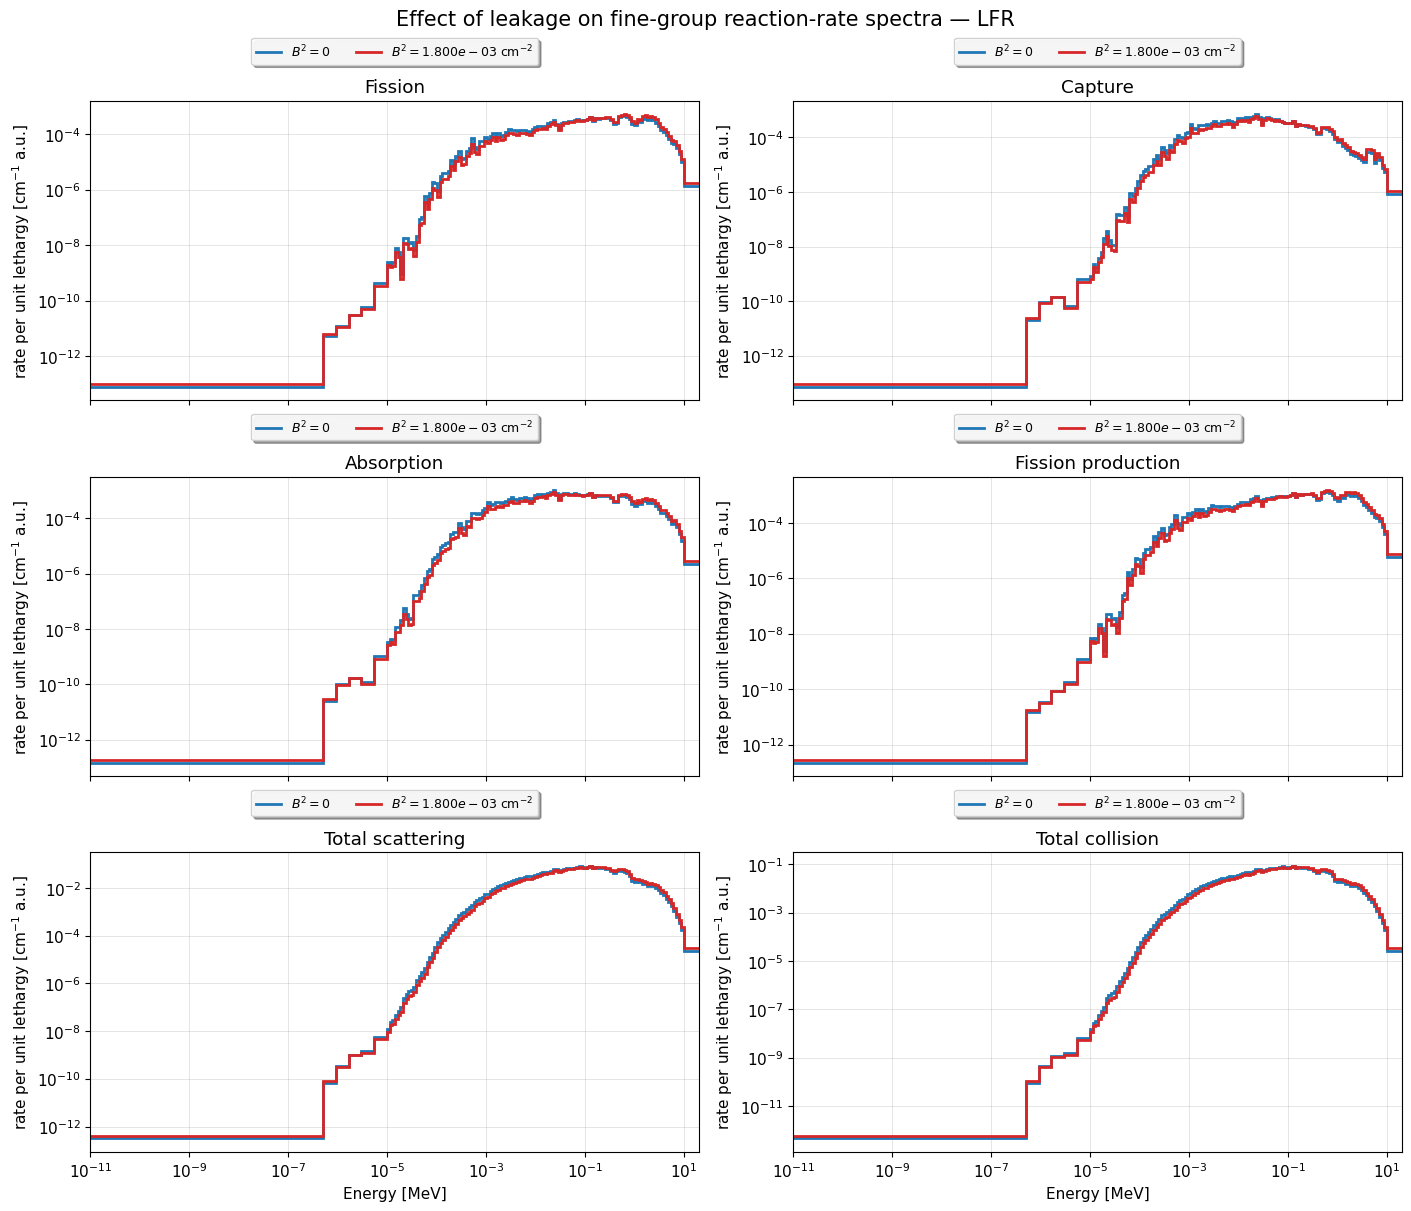

,"integral, B²=0","integral, selected B²",relative change [%]
reaction,,,
Fission,2.182e-03,2.215e-03,1.487e+00
Capture,2.598e-03,2.279e-03,-1.229e+01
Absorption,4.780e-03,4.493e-03,-6.000e+00
Fission production,6.372e-03,6.483e-03,1.734e+00
Total scattering,3.393e-01,3.271e-01,-3.580e+00
Total collision,3.441e-01,3.316e-01,-3.614e+00


In [9]:
# --- Define the groupwise cross section associated with each principal rate
reaction_cross_sections = {
    "Fission": reference.Fiss,
    "Capture": reference.Capt,
    "Absorption": reference.Fiss + reference.Capt,
    "Fission production": reference.Nubar * reference.Fiss,
    "Total scattering": reference.S0.sum(axis=0),
    "Total collision": reference.Tot,
}
du_fine = np.log(reference.edges[:-1] / reference.edges[1:])

# --- Plot each reaction-rate spectrum in a separate panel
fig, axes = plt.subplots(3, 2, figsize=(14, 12), sharex=True, constrained_layout=True)
integrated_rate_rows = []
for ax, (name, xs_vector) in zip(axes.flat, reaction_cross_sections.items()):
    rate_infinite = xs_vector * infinite_solution["phi"]
    rate_leaking = xs_vector * fine_solution["phi"]

    step_plot(ax, reference.edges, rate_infinite / du_fine, color="C0", lw=2.0,
              label=r"$B^2=0$")
    step_plot(ax, reference.edges, rate_leaking / du_fine, color="C3", lw=2.0,
              label=rf"$B^2={B2:.3e}$ cm$^{{-2}}$")
    ax.set(xscale="log", yscale="log", title=name,
           ylabel=r"rate per unit lethargy [cm$^{-1}$ a.u.]")
    ax.legend(fontsize=9, shadow=True, loc="lower center", framealpha=0.9, bbox_to_anchor=(0.5, 1.10), ncol=2)
    ax.set_xlim(x_lim)
    add_major_minor_grid(ax)

    integrated_infinite = rate_infinite.sum()
    integrated_leaking = rate_leaking.sum()
    integrated_rate_rows.append({
        "reaction": name,
        "integral, B²=0": integrated_infinite,
        "integral, selected B²": integrated_leaking,
        "relative change [%]": 100.0 * (integrated_leaking / integrated_infinite - 1.0),
    })

# --- Add common energy labels and tabulate the integrated-rate changes
for ax in axes[-1, :]:
    ax.set_xlabel("Energy [MeV]")
fig.suptitle(f"Effect of leakage on fine-group reaction-rate spectra — {SYSTEM}", fontsize=15)
plt.show()

integrated_rate_table = pd.DataFrame(integrated_rate_rows).set_index("reaction")
display(integrated_rate_table.style.format("{:.3e}"))

## 7. Collapsing and the new eigenvalue solution

Every entry of `CUSTOM_BOUNDARIES` defines one coarse structure. All boundaries are checked against the selected fine grid. Structures are labelled by their group count and an occurrence letter: for example, two different four-group structures become `4G_A` and `4G_B`. The label selected by `PLOT_GRID` is used in the detailed plots.

In [10]:
# --- Validate every custom grid and generate labels such as 4G_A and 4G_B
requested_grids = prepare_custom_grids(reference.edges, CUSTOM_BOUNDARIES)

# --- Collapse the data and solve each coarse eigenvalue problem
collapsed = {}
for grid_id, edges in requested_grids.items():
    data_c = collapse(reference, fine_solution["phi"], edges, DIFFUSION_COLLAPSE)
    collapsed[grid_id] = {"data": data_c, "solution": solve_keff(data_c, B2)}

# --- Fall back if the requested plotting grid is unavailable
if PLOT_GRID not in collapsed:
    PLOT_GRID = next(iter(collapsed))
    print(f"PLOT_GRID is unavailable; using {PLOT_GRID} instead.")

# --- Assemble the formatted k, delta-k, and residual summary
rows = [{
    "grid": f"{reference.nG}G_fine", "k_eff": fine_solution["k"],
    "Δk [pcm]": 0.0, "residual": fine_solution["residual"],
}]
for grid_id, item in collapsed.items():
    sol = item["solution"]
    rows.append({
        "grid": grid_id, "k_eff": sol["k"],
        "Δk [pcm]": 1.0e5 * (sol["k"] - fine_solution["k"]),
        "residual": sol["residual"],
    })
k_table = pd.DataFrame(rows).set_index("grid")
k_table.style.format({"k_eff": "{:.5f}", "Δk [pcm]": "{:.2f}", "residual": "{:.2e}"})

,k_eff,Δk [pcm],residual
grid,,,
120G_fine,1.00717,0.00,1.24e-14
8G_A,1.00717,-0.00,7.06e-16
4G_A,1.00717,-0.00,3.88e-16
2G_A,1.00717,-0.00,2.68e-16
1G_A,1.00717,-0.00,1.34e-16


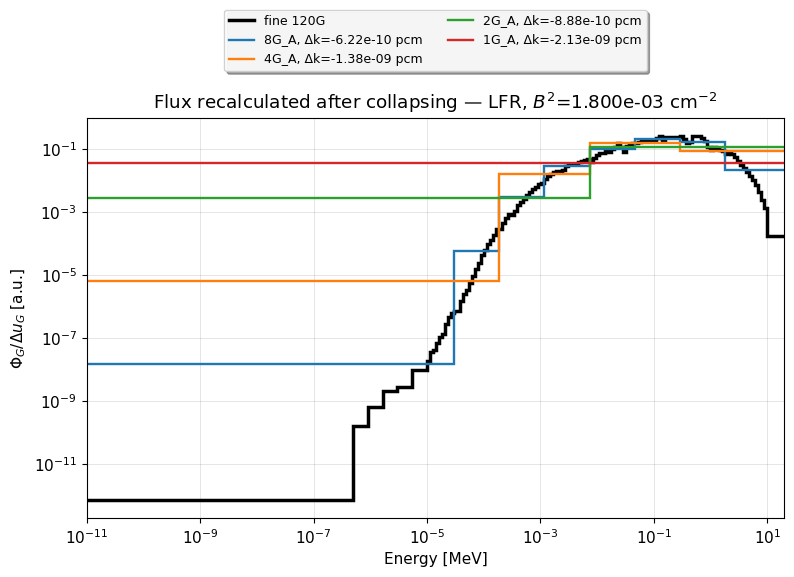

In [11]:
# --- Plot the fine solution and every recalculated collapsed solution
fig, ax = plt.subplots(figsize=(9, 5.2))
plot_flux(ax, reference, fine_solution["phi"], color="black", lw=2.5,
          label=f"fine {reference.nG}G")
for grid_id, item in collapsed.items():
    plot_flux(ax, item["data"], item["solution"]["phi"], lw=1.7,
              label=f"{grid_id}, Δk={1e5*(item['solution']['k']-fine_solution['k']):+.2e} pcm")
ax.set(xscale="log", yscale="log", xlabel="Energy [MeV]", ylabel=r"$\Phi_G/\Delta u_G$ [a.u.]",
       title=rf"Flux recalculated after collapsing — {SYSTEM}, $B^2$={B2:.3e} cm$^{{-2}}$")
ax.set_xlim(x_lim)
add_major_minor_grid(ax)
ax.legend(ncol=2, bbox_to_anchor=(0.5, 1.10), loc="lower center", fontsize=9, shadow=True, framealpha=0.9)
plt.show()

## 8. Collapsed multigroup constants

Black denotes the fine structure, while color denotes the structure selected by `PLOT_GRID`. Cross sections are group averages.

The stored $\chi_g$ values are group-integrated emission probabilities and satisfy $\sum_g\chi_g=1$. To compare different group structures without artificially raising the coarse curve, the plot shows $\chi_g/\Delta u_g$. Its area with respect to lethargy is therefore unity for both structures.

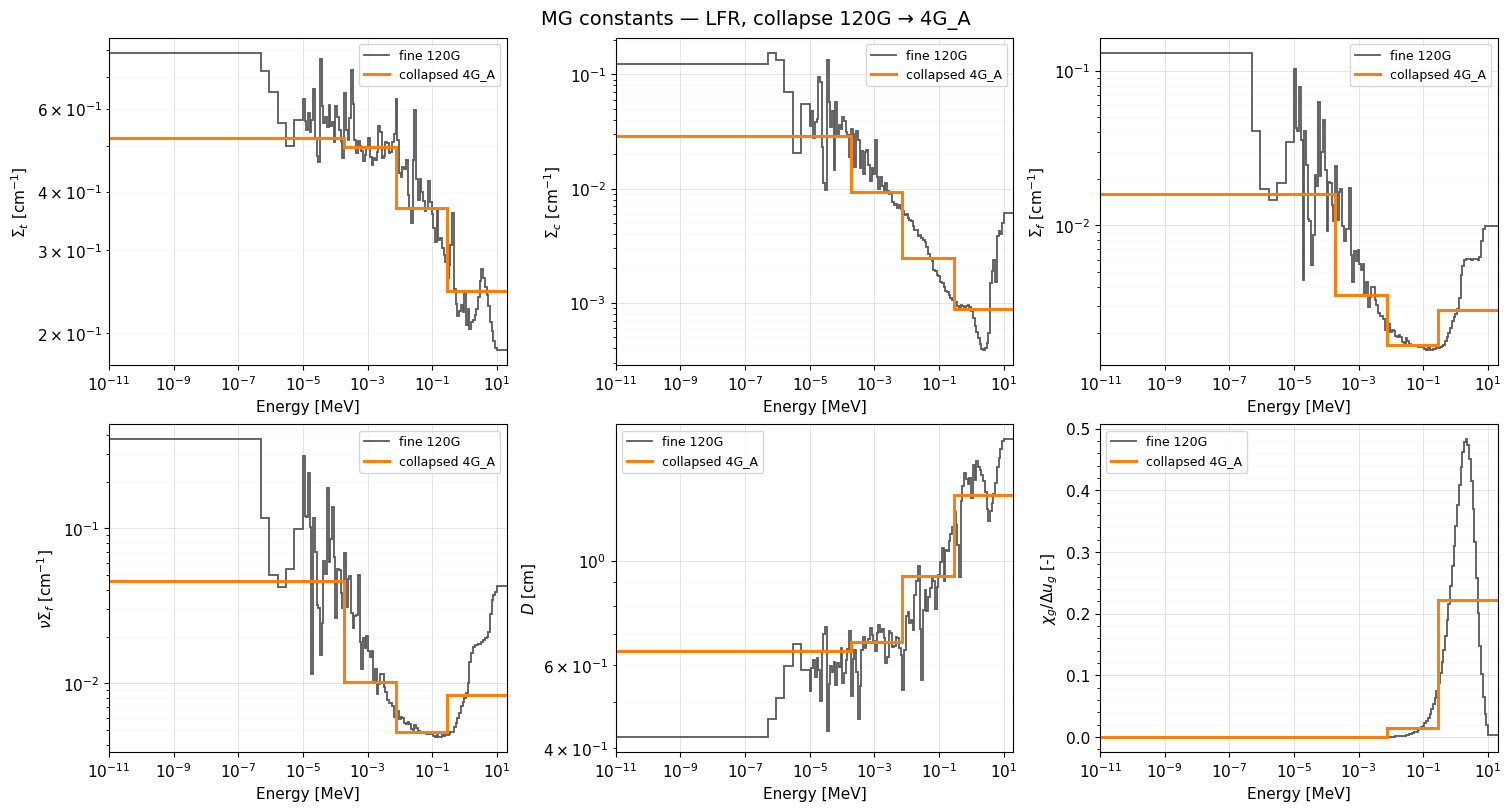

Fine χ sum / lethargy-area      = 1.00000 / 1.00000
Collapsed χ sum / lethargy-area = 1.00000 / 1.00000


In [12]:
# --- Select the coarse dataset used in the detailed diagnostics
selected = collapsed[PLOT_GRID]["data"]
# --- Define the six quantities shown in the comparison panel
quantities = [
    ("Tot", r"$\Sigma_t$ [cm$^{-1}$]", True),
    ("Capt", r"$\Sigma_c$ [cm$^{-1}$]", True),
    ("Fiss", r"$\Sigma_f$ [cm$^{-1}$]", True),
    ("Nsf", r"$\nu\Sigma_f$ [cm$^{-1}$]", True),
    ("Diffcoef", r"$D$ [cm]", True),
    ("Chit", r"$\chi_g/\Delta u_g$ [-]", False),
]

# --- Convert each quantity to a comparable representation and plot it
fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
for ax, (key, ylabel, log_y) in zip(axes.flat, quantities):
    if key == "Nsf":
        fine_values = reference.Nubar * reference.Fiss
        coarse_values = selected.Nubar * selected.Fiss
    elif key == "Chit":
        fine_du = np.log(reference.edges[:-1] / reference.edges[1:])
        coarse_du = np.log(selected.edges[:-1] / selected.edges[1:])
        fine_values = reference.Chit / fine_du
        coarse_values = selected.Chit / coarse_du
    else:
        fine_values = getattr(reference, key)
        coarse_values = getattr(selected, key)

    step_plot(ax, reference.edges, fine_values, color="0.35", lw=1.3, label=f"fine {reference.nG}G")
    step_plot(ax, selected.edges, coarse_values, color="C1", lw=2.2, label=f"collapsed {PLOT_GRID}")
    ax.set_xscale("log")
    if log_y and np.all(fine_values > 0) and np.all(coarse_values > 0):
        ax.set_yscale("log")
    ax.set(xlabel="Energy [MeV]", ylabel=ylabel)
    ax.set_xlim(x_lim)
    add_major_minor_grid(ax)
    ax.legend(fontsize=9)
fig.suptitle(f"MG constants — {SYSTEM}, collapse {reference.nG}G → {PLOT_GRID}", fontsize=14)
plt.show()

# --- Verify both the discrete chi sum and its lethargy-density area
fine_chi_area = np.dot(reference.Chit / fine_du, fine_du)
coarse_chi_area = np.dot(selected.Chit / coarse_du, coarse_du)
print(f"Fine χ sum / lethargy-area      = {reference.Chit.sum():.5f} / {fine_chi_area:.5f}")
print(f"Collapsed χ sum / lethargy-area = {selected.Chit.sum():.5f} / {coarse_chi_area:.5f}")

### Fine and collapsed scattering matrices

The stored and calculated convention remains

$$S_{g,g'}=\Sigma_{s,g'\rightarrow g},$$

that is, `S0[arrival, departure]`. The visualization now uses this stored orientation directly: rows represent arrival groups and columns represent departure groups. No calculation or collapsed constant is changed.

The multigroup ordering runs from high to low energy: group 0 is the highest-energy group, and the group index increases as energy decreases. The plot therefore places group 0 at the **top-left**, with indices increasing to the right and downward; the matrix diagonal runs from top-left to bottom-right. For a 120-group structure, the group indices are 0–119, while the plotted cell-boundary indices run from 0 to 120.

With rows = arrival and columns = departure, down-scattering has `arrival index > departure index` and is consequently displayed below the diagonal (the mathematically lower-triangular part). This orientation applies to the visualization and is also the native storage convention of `S0`.

Both panels use the fine-group boundary index as their coordinate:

- thin, transparent gray lines mark every fine-group boundary;
- thick red lines mark the boundaries of the selected coarse structure;
- the right panel draws each collapsed element over the fine-group interval represented by that macrogroup.

Using the same coordinates and color normalization makes the aggregation from the original matrix to the collapsed blocks directly visible.

,fine-grid boundary index,energy [MeV]
coarse boundary,,
0,0,2.000000e+01
1,30,2.885207e-01
2,60,7.366423e-03
3,90,1.880773e-04
4,120,1.000000e-11


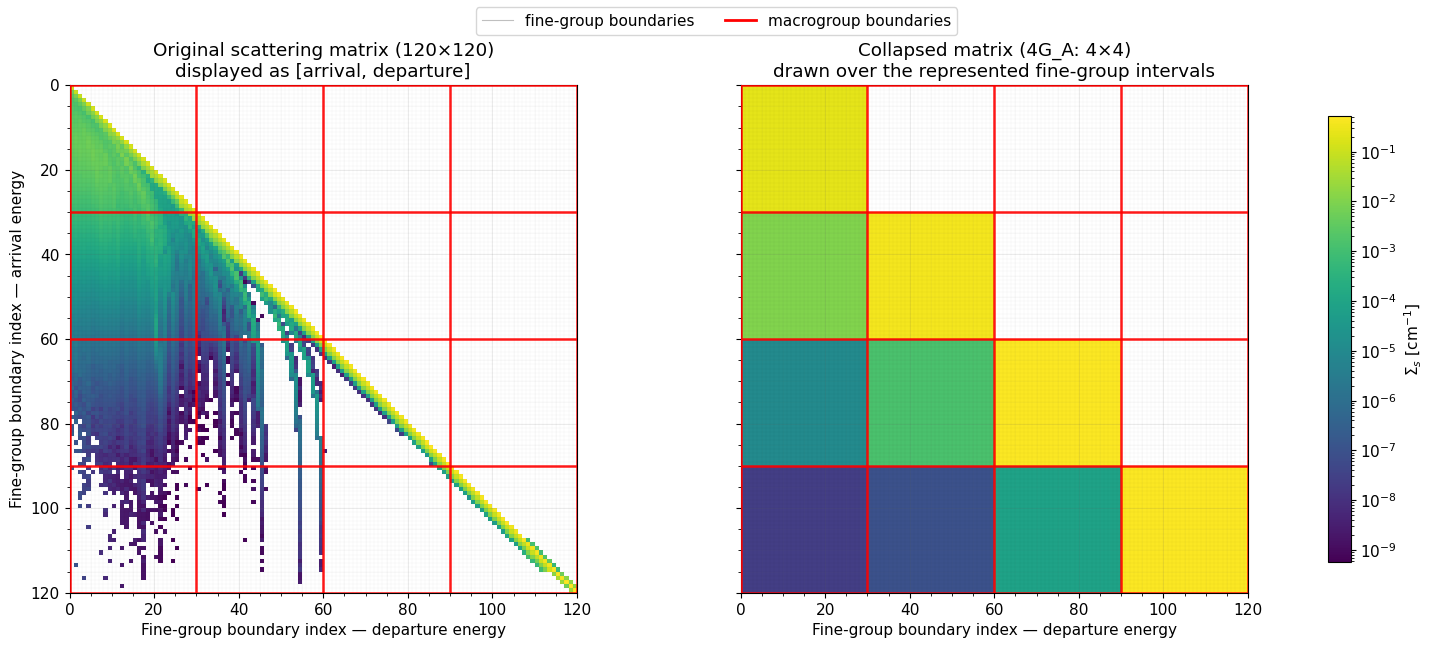

In [13]:
from matplotlib.colors import LogNorm
from matplotlib.lines import Line2D

# --- Map every coarse energy boundary to its position in the fine grid
macro_indices = []
for energy in selected.edges:
    index_in_fine_grid = int(np.argmin(np.abs(reference.edges - energy)))
    if not np.isclose(reference.edges[index_in_fine_grid], energy, rtol=1.0e-8, atol=1.0e-14):
        raise ValueError(f"Coarse boundary {energy:.8e} MeV is not present in the fine grid.")
    macro_indices.append(index_in_fine_grid)
macro_indices = np.asarray(macro_indices)
fine_indices = np.arange(reference.nG + 1)

# --- Report the energy and fine-grid index of every macrogroup boundary
boundary_table = pd.DataFrame({
    "coarse boundary": np.arange(selected.nG + 1),
    "fine-grid boundary index": macro_indices,
    "energy [MeV]": selected.edges,
}).set_index("coarse boundary")
display(boundary_table.style.format({"energy [MeV]": "{:.6e}"}))

# --- Build one logarithmic color normalization shared by both matrices
positive_values = np.concatenate([
    reference.S0[reference.S0 > 0.0],
    selected.S0[selected.S0 > 0.0],
])
if positive_values.size == 0:
    raise ValueError("The scattering matrices contain no positive entries.")
normalization = LogNorm(vmin=positive_values.min(), vmax=positive_values.max())
cmap = plt.get_cmap("viridis").copy()
cmap.set_bad("white")

# --- Use the stored orientation for display: rows=arrival, columns=departure
# --- Draw fine and collapsed matrices on the same fine-index coordinate system
fig, axes = plt.subplots(1, 2, figsize=(15, 6.4), sharex=True, sharey=True,
                         constrained_layout=True)
fine_mesh = axes[0].pcolormesh(
    fine_indices, fine_indices, np.ma.masked_less_equal(reference.S0, 0.0),
    cmap=cmap, norm=normalization, shading="flat",
)
axes[1].pcolormesh(
    macro_indices, macro_indices, np.ma.masked_less_equal(selected.S0, 0.0),
    cmap=cmap, norm=normalization, shading="flat",
)

# --- Overlay transparent fine-group lines and thick red macrogroup boundaries
for ax in axes:
    for boundary in fine_indices:
        ax.axvline(boundary, color="black", lw=0.25, alpha=0.08, zorder=3)
        ax.axhline(boundary, color="black", lw=0.25, alpha=0.08, zorder=3)
    for boundary in macro_indices:
        ax.axvline(boundary, color="red", lw=1.8, alpha=0.9, zorder=4)
        ax.axhline(boundary, color="red", lw=1.8, alpha=0.9, zorder=4)
    ax.set_aspect("equal")
    ax.set_xlim(0, reference.nG)
    # --- Put group 0 at the top and increase MG indices toward lower energy
    ax.set_ylim(reference.nG, 0)
    ax.set_xlabel("Fine-group boundary index — departure energy")
    add_major_minor_grid(ax, major_alpha=0.12, minor_alpha=0.05, axisbelow=False)

# --- Label matrix orientation and explain the two overlaid grids
axes[0].set_ylabel("Fine-group boundary index — arrival energy")
axes[0].set_title(f"Original scattering matrix ({reference.nG}×{reference.nG})\ndisplayed as [arrival, departure]")
axes[1].set_title(
    f"Collapsed matrix ({PLOT_GRID}: {selected.nG}×{selected.nG})\n"
    "drawn over the represented fine-group intervals"
)
legend_handles = [
    Line2D([0], [0], color="black", lw=0.8, alpha=0.25, label="fine-group boundaries"),
    Line2D([0], [0], color="red", lw=2.0, label="macrogroup boundaries"),
]
fig.legend(handles=legend_handles, loc="outside upper center", ncol=2)
fig.colorbar(fine_mesh, ax=axes, label=r"$\Sigma_s$ [cm$^{-1}$]", shrink=0.88)
plt.show()

## 9. Diffusion collapsing and the $P_0$ sum rule

Rate-preserving collapse also preserves the total collision rate because, group by group,

$$
\Sigma_{t,G}=\Sigma_{c,G}+\Sigma_{f,G}+\sum_H\Sigma_{s,G\to H}.
$$

For these $P_0$ data, $\Sigma_{tr}=\Sigma_t$ and $D=1/(3\Sigma_{tr})$. The `transport` option preserves the transport rate and then reconstructs $D$. The `direct-D` option instead preserves leakage by averaging $D$ directly; after reconstructing $\Sigma_{tr,D}=1/(3D_G)$, the identity with the collision sum is no longer guaranteed.

The table evaluates both methods on the structure selected by `PLOT_GRID`, regardless of the active option.

,Σt rate,reaction-sum rate,1/(3D) rate,reaction sum vs Σt [%],1/(3D) vs reaction sum [%],leakage error [%]
method,,,,,,
transport,3.316e-01,3.316e-01,3.316e-01,-2.220e-14,0.000e+00,-2.259e+00
direct-D,3.316e-01,3.316e-01,3.241e-01,-2.220e-14,-2.281e+00,2.220e-14


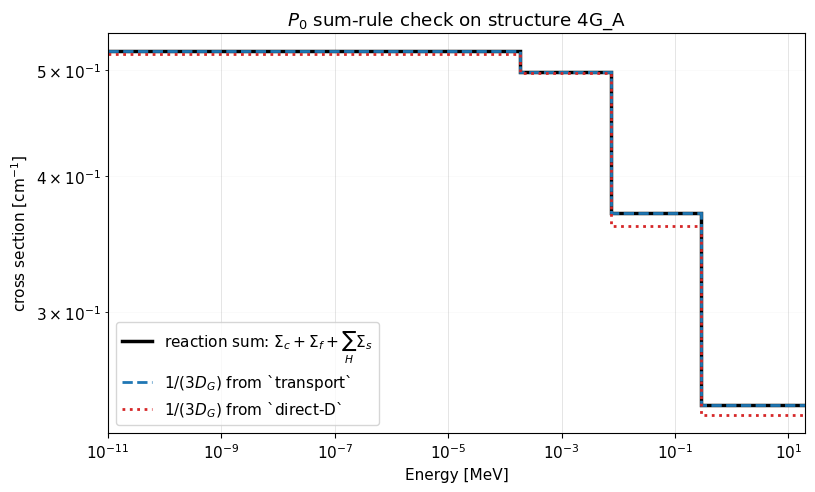

In [14]:
# --- Evaluate rates and sum-rule defects for one diffusion-collapse method
def diffusion_diagnostics(data, phi, edges, b2, mode):
    coarse = collapse(data, phi, edges, mode)
    Phi = coarse.collapse_flux
    # --- Compare the reaction sum with the cross section implied by each D
    reaction_sum = coarse.Capt + coarse.Fiss + coarse.S0.sum(axis=0)
    sigma_from_D = 1.0 / (3.0 * coarse.Diffcoef)

    total_rate = np.dot(coarse.Tot, Phi)
    reaction_sum_rate = np.dot(reaction_sum, Phi)
    transport_rate = np.dot(sigma_from_D, Phi)
    fine_leakage = np.dot(data.Diffcoef * b2, phi)
    coarse_leakage = np.dot(coarse.Diffcoef * b2, Phi)

    return coarse, {
        "method": mode,
        "Σt rate": total_rate,
        "reaction-sum rate": reaction_sum_rate,
        "1/(3D) rate": transport_rate,
        "reaction sum vs Σt [%]": 100.0 * (reaction_sum_rate / total_rate - 1.0),
        "1/(3D) vs reaction sum [%]": 100.0 * (transport_rate / reaction_sum_rate - 1.0),
        "leakage error [%]": (
            np.nan if fine_leakage == 0.0
            else 100.0 * (coarse_leakage / fine_leakage - 1.0)
        ),
    }


# --- Run the same diagnostic for both available methods
transport_data, transport_diag = diffusion_diagnostics(
    reference, fine_solution["phi"], selected.edges, B2, "transport"
)
direct_D_data, direct_D_diag = diffusion_diagnostics(
    reference, fine_solution["phi"], selected.edges, B2, "direct-D"
)
# --- Tabulate total-rate, transport-rate, sum-rule, and leakage errors
sum_rule_table = pd.DataFrame([transport_diag, direct_D_diag]).set_index("method")
display(sum_rule_table.style.format("{:.3e}"))

reaction_sum = transport_data.Capt + transport_data.Fiss + transport_data.S0.sum(axis=0)
fig, ax = plt.subplots(figsize=(9, 5.2))
step_plot(ax, selected.edges, reaction_sum, color="black", lw=2.5,
          label=r"reaction sum: $\Sigma_c+\Sigma_f+\sum_H\Sigma_s$")
step_plot(ax, selected.edges, 1.0/(3.0*transport_data.Diffcoef), color="C0", lw=2.0, ls="--",
          label=r"$1/(3D_G)$ from `transport`")
step_plot(ax, selected.edges, 1.0/(3.0*direct_D_data.Diffcoef), color="C3", lw=2.0, ls=":",
          label=r"$1/(3D_G)$ from `direct-D`")
ax.set(xscale="log", yscale="log", xlabel="Energy [MeV]", ylabel=r"cross section [cm$^{-1}$]",
       title=rf"$P_0$ sum-rule check on structure {PLOT_GRID}")
ax.set_xlim(x_lim)
add_major_minor_grid(ax)
ax.legend()
plt.show()

## 10. Reaction-rate preservation check

For every collapsed structure, this comparison uses $\Phi_G=\sum_{g\in G}\Phi_g$ obtained from the fine spectrum used for collapsing. This is the mathematical preservation test. Using the recalculated flux from the collapsed problem would mix the collapsing error with the spectral error.

The `k_eff` comparison is included as an additional row, so its fine- and collapsed-model values can be read under the same columns used for the reaction rates. The `Δk` column applies only to this row.

In [15]:
# --- Compute the reference fine-group integral rates and eigenvalue
fine_rates = reaction_rates(reference, fine_solution["phi"], B2)
k_fine = fine_solution["k"]

# --- Compare each collapsed reaction rate with its fine-group reference
rate_rows = []
for grid_id, item in collapsed.items():
    data_c = item["data"]
    coarse_rates = reaction_rates(data_c, data_c.collapse_flux, B2)
    k_collapsed = item["solution"]["k"]
    for reaction, fine_value in fine_rates.items():
        coarse_value = coarse_rates[reaction]
        rel = np.nan if fine_value == 0.0 else 100.0 * (coarse_value / fine_value - 1.0)
        rate_rows.append({
            "grid": grid_id,
            "quantity": reaction,
            "fine rate": fine_value,
            "collapsed rate": coarse_value,
            "collapsed/fine [-]": coarse_value / fine_value if fine_value != 0.0 else np.nan,
            "relative error [%]": rel,
            "Δk [pcm]": np.nan,
        })

    # --- Add k_eff as a row under the same fine and collapsed columns
    rate_rows.append({
        "grid": grid_id,
        "quantity": "k_eff",
        "fine rate": k_fine,
        "collapsed rate": k_collapsed,
        "collapsed/fine [-]": k_collapsed / k_fine,
        "relative error [%]": 100.0 * (k_collapsed / k_fine - 1.0),
        "Δk [pcm]": 1.0e5 * (k_collapsed - k_fine),
    })

# --- Keep numeric results and create a row-aware formatted table for display
rate_table = pd.DataFrame(rate_rows).set_index(["grid", "quantity"])
formatted_rate_table = rate_table.copy().astype(object)
for index, row in rate_table.iterrows():
    is_keff = index[1] == "k_eff"
    formatted_rate_table.loc[index, "fine rate"] = (
        f"{row['fine rate']:.5f}" if is_keff else f"{row['fine rate']:.3e}"
    )
    formatted_rate_table.loc[index, "collapsed rate"] = (
        f"{row['collapsed rate']:.5f}" if is_keff else f"{row['collapsed rate']:.3e}"
    )
    formatted_rate_table.loc[index, "collapsed/fine [-]"] = f"{row['collapsed/fine [-]']:.5f}"
    formatted_rate_table.loc[index, "relative error [%]"] = f"{row['relative error [%]']:.2e}"
    formatted_rate_table.loc[index, "Δk [pcm]"] = f"{row['Δk [pcm]']:.2e}" if is_keff else "—"
display(formatted_rate_table)

fine rate collapsed rate collapsed/fine [-]  \
grid quantity                                                          
8G_A Fission             2.215e-03      2.215e-03            1.00000   
     Capture             2.279e-03      2.279e-03            1.00000   
     Absorption          4.493e-03      4.493e-03            1.00000   
     Fission production  6.483e-03      6.483e-03            1.00000   
     Total scattering    3.271e-01      3.271e-01            1.00000   
     Total               3.316e-01      3.316e-01            1.00000   
     Leakage DB²Φ        1.943e-03      1.943e-03            1.00000   
     k_eff                 1.00717        1.00717            1.00000   
4G_A Fission             2.215e-03      2.215e-03            1.00000   
     Capture             2.279e-03      2.279e-03            1.00000   
     Absorption          4.493e-03      4.493e-03            1.00000   
     Fission production  6.483e-03      6.483e-03            1.00000   
     Total scattering    3.271e-01      3.271e-01            1.00000   
     Total               3.316e-01      3.316e-01            1.00000   
     Leakage DB²Φ        1.943e-03      1.943e-03            1.00000   
     k_eff                 1.00717        1.00717            1.00000   
2G_A Fission             2.215e-03      2.215e-03            1.00000   
     Capture             2.279e-03      2.279e-03            1.00000   
     Absorption          4.493e-03      4.493e-03            1.00000   
     Fission production  6.483e-03      6.483e-03            1.00000   
     Total scattering    3.271e-01      3.271e-01            1.00000   
     Total               3.316e-01      3.316e-01            1.00000   
     Leakage DB²Φ        1.943e-03      1.943e-03            1.00000   
     k_eff                 1.00717        1.00717            1.00000   
1G_A Fission             2.215e-03      2.215e-03            1.00000   
     Capture             2.279e-03      2.279e-03            1.00000   
     Absorption          4.493e-03      4.493e-03            1.00000   
     Fission production  6.483e-03      6.483e-03            1.00000   
     Total scattering    3.271e-01      3.271e-01            1.00000   
     Total               3.316e-01      3.316e-01            1.00000   
     Leakage DB²Φ        1.943e-03      1.943e-03            1.00000   
     k_eff                 1.00717        1.00717            1.00000   

                        relative error [%]   Δk [pcm]  
grid quantity                                          
8G_A Fission                     -4.44e-14          —  
     Capture                     -2.22e-14          —  
     Absorption                  -5.55e-14          —  
     Fission production           2.22e-14          —  
     Total scattering             2.22e-14          —  
     Total                        0.00e+00          —  
     Leakage DB²Φ                 4.44e-14          —  
     k_eff                       -6.22e-13  -6.22e-10  
4G_A Fission                     -2.22e-14          —  
     Capture                     -2.22e-14          —  
     Absorption                  -7.77e-14          —  
     Fission production           2.22e-14          —  
     Total scattering            -2.22e-14          —  
     Total                       -2.22e-14          —  
     Leakage DB²Φ                 2.22e-14          —  
     k_eff                       -1.37e-12  -1.38e-09  
2G_A Fission                     -2.22e-14          —  
     Capture                     -3.33e-14          —  
     Absorption                  -7.77e-14          —  
     Fission production           2.22e-14          —  
     Total scattering             0.00e+00          —  
     Total                       -2.22e-14          —  
     Leakage DB²Φ                 4.44e-14          —  
     k_eff                       -8.77e-13  -8.88e-10  
1G_A Fission                      0.00e+00          —  
     Capture                      0.00e+00          —  
     Abs

grid,1G_A,2G_A,4G_A,8G_A
quantity,,,,
Fission,0.000000e+00,-2.220446e-14,-2.220446e-14,-4.440892e-14
Capture,0.000000e+00,-3.330669e-14,-2.220446e-14,-2.220446e-14
Absorption,-5.551115e-14,-7.771561e-14,-7.771561e-14,-5.551115e-14
Fission production,0.000000e+00,2.220446e-14,2.220446e-14,2.220446e-14
Total scattering,2.220446e-14,0.000000e+00,-2.220446e-14,2.220446e-14
Total,0.000000e+00,-2.220446e-14,-2.220446e-14,0.000000e+00
Leakage DB²Φ,4.440892e-14,4.440892e-14,2.220446e-14,4.440892e-14


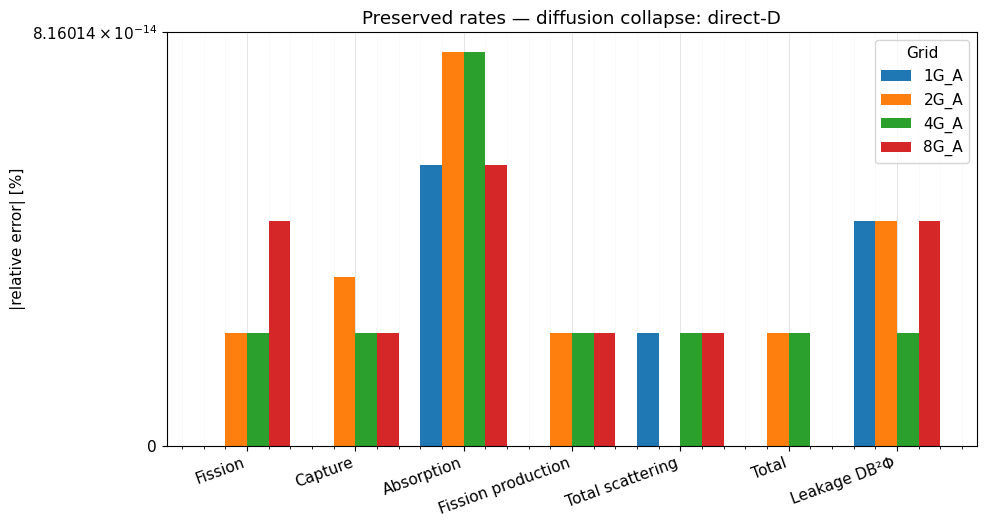

In [16]:
# --- Reshape reaction-rate errors only; k_eff remains in the table above
reaction_error_table = rate_table.drop(index="k_eff", level="quantity")
error_pivot = reaction_error_table["relative error [%]"].unstack("grid")
display(error_pivot)

# --- Plot absolute relative errors on a scale that also shows roundoff
fig, ax = plt.subplots(figsize=(10, 5.4))
x = np.arange(len(error_pivot.index))
width = 0.8 / len(error_pivot.columns)
for j, grid_id in enumerate(error_pivot.columns):
    ax.bar(x + (j - (len(error_pivot.columns)-1)/2)*width,
           np.abs(error_pivot[grid_id].to_numpy()), width=width, label=grid_id)
ax.set_yscale("symlog", linthresh=1.0e-12)
ax.set_xticks(x, error_pivot.index, rotation=20, ha="right")
ax.set_ylabel("|relative error| [%]")
ax.set_title(f"Preserved rates — diffusion collapse: {DIFFUSION_COLLAPSE}")
add_major_minor_grid(ax)
ax.legend(title="Grid")
plt.tight_layout()
plt.show()

### Interpreting the result

- Fission, capture, absorption, $\nu\Sigma_f$ production, total scattering, and the total collision rate agree within numerical roundoff because the constants were defined to preserve their rates with the fine spectrum.
- With `DIFFUSION_COLLAPSE="transport"`, the transport-cross-section rate and the $P_0$ sum rule are preserved, while leakage is generally not.
- With `DIFFUSION_COLLAPSE="direct-D"`, leakage is preserved instead, while the transport-cross-section rate and the associated sum rule are generally not.
- Consequently, $k$ and the recalculated collapsed flux may differ from the fine solution, especially when very few groups are retained or `B2` is increased.